<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

# Домашнее задание. RAG.

В этом домашнем задании вам предстоит создать туристический RAG, провести EDA и проявить креатив! :)

Вам дан набор данных, содержащий информацию о памятниках, архитектуре и других значимых местах. В данных есть:
* название достопримечательности;
* идентификатор на WikiData;
* город расположения;
* координаты долготы и широты;
* описание (извлеченное из WikiData);
* изображение в формате base64;
* сгенерированное описание изображения (генерация с помощью модели BLIP).

Некоторые из памятников могут встречаться несколько раз, но с различными изображениями, из которых не все могут быть качественными. Для компенсации этого даны текстовые описания.

Часть данных взята с Национальной технологической олимпиады студентов по CV. Базовое решение предполагает использование мультимодального ru-CLIP. Но в данном домашнем задании предлагается решить эту задачу творчески, используя NLP подход.

## Установка и импорт библиотек

In [86]:
!pip install -q gdown torch transformers transformers accelerate bitsandbytes langchain sentence-transformers faiss-gpu openpyxl datasets langchain-community ragatouille umap-learn

In [87]:
!pip install -q langchain-huggingface langchain-text-splitters

In [88]:
!pip install -q "langchain==0.3.27" "langchain-community==0.3.31" "langchain-huggingface==0.3.1" "langchain-text-splitters==0.3.11"

In [89]:
import gdown
import pandas as pd
from tqdm.notebook import tqdm
from typing import Optional, List, Tuple
import matplotlib.pyplot as plt
from langchain_core.documents import Document as LangchainDocument
from sentence_transformers import SentenceTransformer
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores.utils import DistanceStrategy
import numpy as np
import plotly.express as px
from transformers import pipeline
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from ragatouille import RAGPretrainedModel

#------------------------------------------------------------------------------------
# from langchain.text_splitter import ... # выберите другую стратегию разбивки на чанки

# pd.set_option("display.max_colwidth", None)

## Загрузка данных (4 балла)

In [90]:
url = 'https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk'
output = 'file.csv'

gdown.download(url, output, quiet=False)

data = pd.read_csv('file.csv')

Downloading...
From (original): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk
From (redirected): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk&confirm=t&uuid=69215001-5d72-450f-8398-9b2c46ad400e
To: /kaggle/working/file.csv
100%|██████████| 672M/672M [00:02<00:00, 228MB/s]  


In [91]:
data.head()

,Unnamed: 0,Name,WikiData,City,Lon,Lat,description,image,en_txt
0,0,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there are two people that are standing on a tr...
1,1,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed building with a blue and white exterior...
2,2,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
3,3,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
4,4,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a boat that is in the water near a bu...


Для декодирования изображений, закодированных в формате base64, можно использовать следующий код:

In [92]:
import base64
import requests
import matplotlib.pyplot as plt
from PIL import Image
import PIL
from io import BytesIO

In [93]:
def get_image(data):
  image = Image.open(BytesIO(base64.b64decode(data))).convert('RGB')
  return image

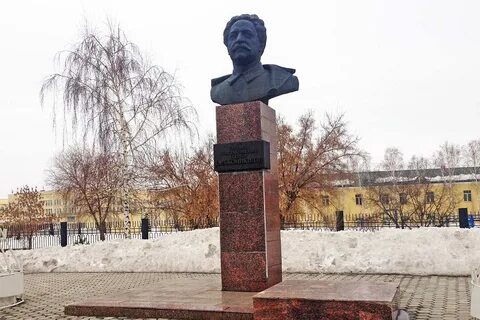

In [94]:
get_image(data.sample(1)['image'].tolist()[0])

В данных есть выбросы — записи, не относящихся к туристическим или историческим объектам. Для очистки данных можно, например, использовать алгоритм TF-IDF: создаем корпус текстов из описаний, применяем TF-IDF, извлекаем наиболее редко или часто встречающиеся слова. Они могут указывать на мусорные данные, такие как мемы, баннеры или личные фото людей. После выделения подозрительных паттернов, можно провести ручную проверку и фильтрацию данных.

Для дальнейшего тестирования и получения чистых сэмплов, рекомендуется взять не менее 100 чистых образцов со стратификацией по городу и названию места. Это можно сделать, выбрав случайным образом несколько образцов из каждой категории (город + название места), чтобы обеспечить равномерное представительство и разнообразие данных.

**!! Важно:** Помните, что чистые сэмплы одного и того же места выдадут примерно одинаковое описание. Есть несколько стратегий, как повысить разнообразие ответов:

- выбор одного самого лучшего:
  - самое длинное описание
  - смое подходящие по мнению LLM
- конкатенация описаний (но важно не сконкатенировать слишком много)

Изображения можно отдать в мета-данные.

In [95]:
for col in data.columns:
    print(f"{col}: {(data[col].isna().sum() / data.shape[0] * 100):.4f}")

Unnamed: 0: 0.0000
Name: 0.0000
WikiData: 17.4662
City: 0.0000
Lon: 0.0000
Lat: 0.0000
description: 17.4662
image: 0.0000
en_txt: 0.0000


получается в полях WikiData, description целых 17% пропусков

In [96]:
data.value_counts("WikiData")

WikiData
Q4516884     123
Q4500767     117
Q4319898     116
Q4087775     100
Q4504600      90
            ... 
Q51946123     27
Q99522676     27
Q4165268      26
Q2494278      26
Q55154121     26
Name: count, Length: 296, dtype: int64

In [97]:
pd.crosstab(data["WikiData"].isna(), data["description"].isna())

description,False,True
WikiData,,
False,12078,0
True,0,2556


#### проверим, можно ли восстановить информацию из колонок с пропещенными значениями по дополнительным данным из бд

In [98]:
coords_missing = data.loc[data["WikiData"].isna(), ["Lon", "Lat"]].drop_duplicates()
coords_missing

,Lon,Lat
7761,40.398632,56.126774
7791,40.413624,56.132153
7821,40.396053,56.126419
7880,40.401737,56.130810
7909,40.397057,56.126881
...,...,...
10175,40.413628,56.131805
10234,40.421490,56.130661
10891,39.880016,57.625282
11291,39.870636,57.624523


In [99]:
data_known = data.loc[data["WikiData"].notna(), ["Lon", "Lat", "Name", "City", "WikiData"]]
data_known

,Lon,Lat,Name,City,WikiData
0,60.600349,56.845398,Динамо,Екатеринбург,Q37996725
1,60.600349,56.845398,Динамо,Екатеринбург,Q37996725
2,60.600349,56.845398,Динамо,Екатеринбург,Q37996725
3,60.600349,56.845398,Динамо,Екатеринбург,Q37996725
4,60.600349,56.845398,Динамо,Екатеринбург,Q37996725
...,...,...,...,...,...
14629,39.876846,57.609852,Ярославское художественное училище,Ярославль,Q4538931
14630,39.876846,57.609852,Ярославское художественное училище,Ярославль,Q4538931
14631,39.876846,57.609852,Ярославское художественное училище,Ярославль,Q4538931
14632,39.876846,57.609852,Ярославское художественное училище,Ярославль,Q4538931


In [100]:
matches_coords = data_known.merge(coords_missing, on=["Lon", "Lat"], how="inner").drop_duplicates()
matches_coords

,Lon,Lat,Name,City,WikiData


Получается, координаты нигде не совпадают. Тогда попробуем поискать по Name, City

In [101]:
missing_names_cities = data.loc[data["WikiData"].isna(), ["Name", "City"]].drop_duplicates()
missing_names_cities

,Name,City
7761,Мемориальная мастерская им. Французова,Владимир
7791,Выставочный зал,Владимир
7821,Музей хрусталя и стекла XVIII-XXI веков,Владимир
7880,Музей непридуманных историй,Владимир
7909,Военно-историческая экспозиция (Золотые ворота),Владимир
...,...,...
10175,"Часовня святого Николая Чудотворца, архиеписко...",Владимир
10234,Владимирским железнодорожникам погибшим в ВОВ,Владимир
10891,Выставочный зал имени Нужина,Ярославль
11291,Дом-музей Максима Богдановича,Ярославль


In [102]:
matches_city_name = data_known.merge(missing_names_cities, on=["Name", "City"], how="inner")
matches_city_name

,Lon,Lat,Name,City,WikiData


И опять не получилось найти совпадения. Пока что оставим строчки, тк в них в целом может содержаться важная информация, но будем иметь в виду, что полноценно восстановить их не получится

Проверим качество en_txt там, где нет описания, чтобы если что подставлять его

In [103]:
en_txt_examples = data.loc[data["description"].isna(), ["Name", "City", "en_txt"]]
list(en_txt_examples.sample(10).itertuples(index=False, name=None))

[('Князю Владимиру и святителю Фёдору',
  'Владимир',
  'there is a statue of a man riding a horse with a flag on top'),
 ('Мемориальная мастерская им. Французова',
  'Владимир',
  'there is a small store with a sign on the front of it'),
 ('Мальчик с рогаткой', 'Владимир', 'boy with a bow and arrow in his hands'),
 ('П.И. Чайковский',
  'Владимир',
  'a close up of a picture of a young boy in a suit'),
 ('Библиотечная лужайка',
  'Владимир',
  'a close up of a sign with a sun and a tree'),
 ('Владимир', 'Владимир', 'arafed view of a city with a church and a road'),
 ('Виртуальный концертный зал',
  'Владимир',
  'arafed view of a concert with a band performing on stage'),
 ('Владимирская гвардейская ракетная Витебская Краснознамённая армия',
  'Владимир',
  'a man holding a flag with a picture of a man holding a flag'),
 ('Панно на стене',
  'Владимир',
  'a close up of a living room with a couch and a painting'),
 ('Домовая церковь Елисаветы Феодоровны',
  'Владимир',
  'arafed brick

Если так поперебирать .sample() можно понять, что в целом эти описания соответствуют действительности. Да, если тексты, где просто описывается толпа, люди и тд, но в основном это довольно информативно

#### Попробуем собрать текст для поиска

In [104]:
descr = data["description"].fillna(data["en_txt"])
data["search_text"] = ("Name: " + data["Name"] + ". City: " + data["City"] + ". Description: " + descr)
data["search_text"].head()

0    Name: Динамо. City: Екатеринбург. Description:...
1    Name: Динамо. City: Екатеринбург. Description:...
2    Name: Динамо. City: Екатеринбург. Description:...
3    Name: Динамо. City: Екатеринбург. Description:...
4    Name: Динамо. City: Екатеринбург. Description:...
Name: search_text, dtype: object

#### Теперь попробуем собрать документ для каждого места

Для этого надо сгруппировать по WikiData строчки и дополнить описания там, где они различные (где одинаковые просто дропнуть дубликаты)

In [105]:
all_wiki_ids = data["WikiData"].value_counts()
ids_matches = data.merge(all_wiki_ids, on=["WikiData"], how="right")
ids_matches.head()

,Unnamed: 0,Name,WikiData,City,Lon,Lat,description,image,en_txt,search_text,count
0,2215,Чкаловская лестница,Q4516884,Нижний Новгород,44.009453,56.330681,лестница на Волжском откосе в Нижнем Новгороде,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,a view of a circular staircase leading to a bu...,Name: Чкаловская лестница. City: Нижний Новгор...,123
1,2216,Чкаловская лестница,Q4516884,Нижний Новгород,44.009453,56.330479,лестница на Волжском откосе в Нижнем Новгороде,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,a view of a circular staircase leading to a bu...,Name: Чкаловская лестница. City: Нижний Новгор...,123
2,2217,Чкаловская лестница,Q4516884,Нижний Новгород,44.009453,56.330681,лестница на Волжском откосе в Нижнем Новгороде,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed view of a city at night with a circular...,Name: Чкаловская лестница. City: Нижний Новгор...,123
3,2218,Чкаловская лестница,Q4516884,Нижний Новгород,44.009453,56.330479,лестница на Волжском откосе в Нижнем Новгороде,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed view of a city at night with a circular...,Name: Чкаловская лестница. City: Нижний Новгор...,123
4,2219,Чкаловская лестница,Q4516884,Нижний Новгород,44.009453,56.330681,лестница на Волжском откосе в Нижнем Новгороде,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed view of a large building with a steep h...,Name: Чкаловская лестница. City: Нижний Новгор...,123


In [106]:
unique_search_texts = data.groupby("WikiData")["search_text"].nunique()
unique_search_texts

WikiData
Q100270892    1
Q100701435    1
Q100882660    1
Q104554178    1
Q104776528    1
             ..
Q97999957     1
Q98381215     1
Q99522676     1
Q99622643     1
Q99929827     1
Name: search_text, Length: 296, dtype: int64

In [107]:
unique_search_texts.unique()

array([1, 2])

Там где один уникальный, надо будет просто использовать его и не брать повторы, там где несколько - посмотрим, что там вообще

In [108]:
st_matches = data.merge(unique_search_texts[unique_search_texts == 2], on=["WikiData"], how="inner")
st_matches.head()

,Unnamed: 0,Name,WikiData,City,Lon,Lat,description,image,en_txt,search_text_x,search_text_y
0,41,№32 Дом обороны,Q55209768,Екатеринбург,60.601315,56.834167,здание в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a large building with a helicopter on...,Name: №32 Дом обороны. City: Екатеринбург. Des...,2
1,42,№32 Дом обороны,Q55209768,Екатеринбург,60.601315,56.834167,здание в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed building with a sign on top of it in a ...,Name: №32 Дом обороны. City: Екатеринбург. Des...,2
2,43,№32 Дом обороны,Q55209768,Екатеринбург,60.601315,56.834167,здание в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a small plane that is on top of a bui...,Name: №32 Дом обороны. City: Екатеринбург. Des...,2
3,44,№32 Дом обороны,Q55209768,Екатеринбург,60.601315,56.834167,здание в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,cars parked in front of a building with a plan...,Name: №32 Дом обороны. City: Екатеринбург. Des...,2
4,45,№32 Дом обороны,Q55209768,Екатеринбург,60.601315,56.834167,здание в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,cars parked in front of a building with a larg...,Name: №32 Дом обороны. City: Екатеринбург. Des...,2


In [109]:
texts = st_matches[["WikiData", "search_text_x"]].dropna().drop_duplicates().sort_values("WikiData")
with pd.option_context("display.max_colwidth", None):
    display(texts[["WikiData", "search_text_x"]])

,WikiData,search_text_x
1651,Q1078595,Name: Спасо-Преображенский собор. City: Ярославль. Description: монастырь в Ярославле
1611,Q1078595,Name: Спасо-Преображенский монастырь. City: Ярославль. Description: монастырь в Ярославле
604,Q18406802,"Name: Дмитровская башня. City: Нижний Новгород. Description: проездная башня Нижегородского кремля, один из символов Нижнего Новгорода"
570,Q18406802,"Name: Дмитриевская башня. City: Нижний Новгород. Description: проездная башня Нижегородского кремля, один из символов Нижнего Новгорода"
763,Q19692529,Name: Ивановская башня. City: Нижний Новгород. Description: проездная башня Нижегородского кремля
734,Q19692529,Name: Экспозиция «Подвиг народного единства». City: Нижний Новгород. Description: проездная башня Нижегородского кремля
343,Q1984395,Name: №16 Усадьба Расторгуева-Харитонова. City: Екатеринбург. Description: здание в Екатеринбурге
370,Q1984395,Name: Усадьба Расторгуевых — Харитоновых. City: Екатеринбург. Description: здание в Екатеринбурге
540,Q27921892,Name: Доходный дом купца Чувильдина. City: Екатеринбург. Description: Дом купца Чувильдина
510,Q27921892,Name: №29 Дом В.И. Чувильдина. City: Екатеринбург. Description: Дом купца Чувильдина


как можно заметить, отличия только в названиях (как правило). тогда просто возьму те, которые чаще встраются в датасете

#### Соберем полный документ для каждой достопримечательности, пока что не трогая разные картинки

На этом этапе попробую просто дропнуть строчки, где нет WikiData

In [110]:
data.dropna(inplace=True)
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12078 entries, 0 to 14633
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   12078 non-null  int64  
 1   Name         12078 non-null  object 
 2   WikiData     12078 non-null  object 
 3   City         12078 non-null  object 
 4   Lon          12078 non-null  float64
 5   Lat          12078 non-null  float64
 6   description  12078 non-null  object 
 7   image        12078 non-null  object 
 8   en_txt       12078 non-null  object 
 9   search_text  12078 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 1.0+ MB


In [111]:
descr = data["description"].fillna(data["en_txt"])
data["search_text"] = ("Name: " + data["Name"] + ". City: " + data["City"] + ". Description: " + descr)
data["search_text"].head()

0    Name: Динамо. City: Екатеринбург. Description:...
1    Name: Динамо. City: Екатеринбург. Description:...
2    Name: Динамо. City: Екатеринбург. Description:...
3    Name: Динамо. City: Екатеринбург. Description:...
4    Name: Динамо. City: Екатеринбург. Description:...
Name: search_text, dtype: object

In [112]:
cards = data[["WikiData", "Name", "City", "search_text"]].copy()
cards["text_counts"] = cards.groupby(["WikiData", "search_text"])["search_text"].transform("size")

places = cards.sort_values("text_counts", ascending=False, kind="stable").drop_duplicates("WikiData").drop(columns="text_counts")
places

,WikiData,Name,City,search_text
2469,Q15954283,улица Добролюбова,Екатеринбург,Name: улица Добролюбова. City: Екатеринбург. D...
5441,Q4516884,Чкаловская лестница,Нижний Новгород,Name: Чкаловская лестница. City: Нижний Новгор...
2377,Q4474328,улица Февральской Революции,Екатеринбург,Name: улица Февральской Революции. City: Екате...
2131,Q4343452,Добровольцам-танкистам,Екатеринбург,Name: Добровольцам-танкистам. City: Екатеринбу...
2815,Q4477575,Усадьба Тарасова,Екатеринбург,Name: Усадьба Тарасова. City: Екатеринбург. De...
...,...,...,...,...
14461,Q4538889,Ярославский музей-заповедник,Ярославль,Name: Ярославский музей-заповедник. City: Ярос...
14607,Q4538931,Ярославское художественное училище,Ярославль,Name: Ярославское художественное училище. City...
97,Q55154121,№28 Здание городской электростанции «Луч»,Екатеринбург,Name: №28 Здание городской электростанции «Луч...
11205,Q4165268,Дом Болконского,Ярославль,Name: Дом Болконского. City: Ярославль. Descri...


картинки обработаем чуть позже, пока что поработаем с удалением неинформативных объектов с использованием tf-idf

#### Отсеим неинформативные объекты

Можем смотреть по изнчальному датасету data, тк в нашем places просто уникальные WikiData. Если найдется мусор в data, мы его просто дропнем из places

Сделаем классификатор, чтобы посмотреть, какие объекты являются мусорными, а какие нормальными для нас

In [113]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

vectorizer = TfidfVectorizer(ngram_range=(1, 2))
tfidf = vectorizer.fit_transform(data["en_txt"])
tfidf.shape

(12078, 7743)

In [114]:
tfidf.min(), tfidf.mean(), tfidf.max()

(np.float64(0.0), np.float64(0.0005028229593254266), np.float64(1.0))

теперь посмотрим топ-5 фраз с самым большим tf-idf. если это какие-то фразы, не относящиеся к достопримечательностям, надо будет отфильтровать датасет по ним

Unnamed: 0                                                  2215
Name                                   Ново-Тихвинский монастырь
WikiData                                                Q4322970
City                                                Екатеринбург
Lon                                                    60.598354
Lat                                                    56.823097
description                            Ново-Тихвинский монастырь
image          /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...
en_txt         arafed view of a large building with two domes...
search_text    Name: Ново-Тихвинский монастырь. City: Екатери...
Name: 2215, dtype: object
['two domes' 'domes on' 'with two' 'two' 'domes'] [0.485 0.38  0.325 0.285 0.245]


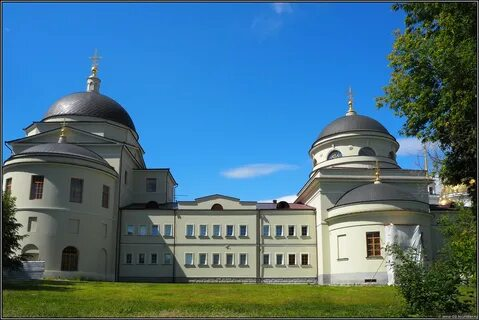

In [115]:
idx = np.random.randint(data.shape[0]-1)

row = tfidf[idx]
names = vectorizer.get_feature_names_out()
top5 = row.data.argsort()[::-1][:5]
print(data.iloc[idx, :])
print(names[row.indices][top5], row.data[top5].round(3))
get_image(data.iloc[idx]["image"])

вручную посмотреть на все такие фотки и отфильтровать невозможно (их 12000), поэтому я написал фразы, которые в теории могут описывать мусор. попробуем посчитать косинусное сходство между остальными представлениями картинок и фильтровать так

In [116]:
from sklearn.metrics.pairwise import cosine_similarity

In [117]:
trash_phrases = [
    "a screenshot of a conversation or text messages",
    "a screenshot of a website or social media page",
    "an advertisement or promotional banner",
    "a logo emblem badge or coat of arms",
    "a meme or cartoon with text",
    "a document certificate or printed text",
    "a person posing for a portrait or selfie",
    "a group of people posing for a picture",
    "a soccer team posing for a group photo",
    "a product or item displayed for sale",
]

trash_vectors = vectorizer.transform(trash_phrases)
similarities = cosine_similarity(tfidf, trash_vectors)

In [118]:
data_scored = data.copy()
data_scored["trash_score"] = similarities.max(axis=1)
data_scored["trash_phrase"] = np.array(trash_phrases)[similarities.argmax(axis=1)]

In [119]:
threshold = 0.35
suspects = data_scored.loc[data_scored["trash_score"] >= threshold].sort_values("trash_score", ascending=False)
suspects[["Name", "en_txt", "trash_score", "trash_phrase"]].head(5)

,Name,en_txt,trash_score,trash_phrase
14258,Школа № 33 имени Карла Маркса,arafed image of a group of people posing for a...,0.884098,a group of people posing for a picture
12364,Памятник жертвам белогвардейского мятежа,arafed group of people posing for a picture in...,0.814436,a group of people posing for a picture
229,Театр кукол,arafed group of people posing for a picture on...,0.813555,a group of people posing for a picture
1168,Театр оперы и балета,arafed group of people posing for a picture on...,0.813555,a group of people posing for a picture
1949,Филармония,arafed group of people posing for a picture on...,0.813555,a group of people posing for a picture


In [120]:
def show_images(images, cols=3):
    cols = min(cols, len(images))
    rows = (len(images) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows), squeeze=False)

    for ax in axes.flat:
        ax.axis("off")

    for ax, encoded in zip(axes.flat, images):
        ax.imshow(get_image(encoded).convert("RGB"))

    fig.tight_layout()
    plt.show()

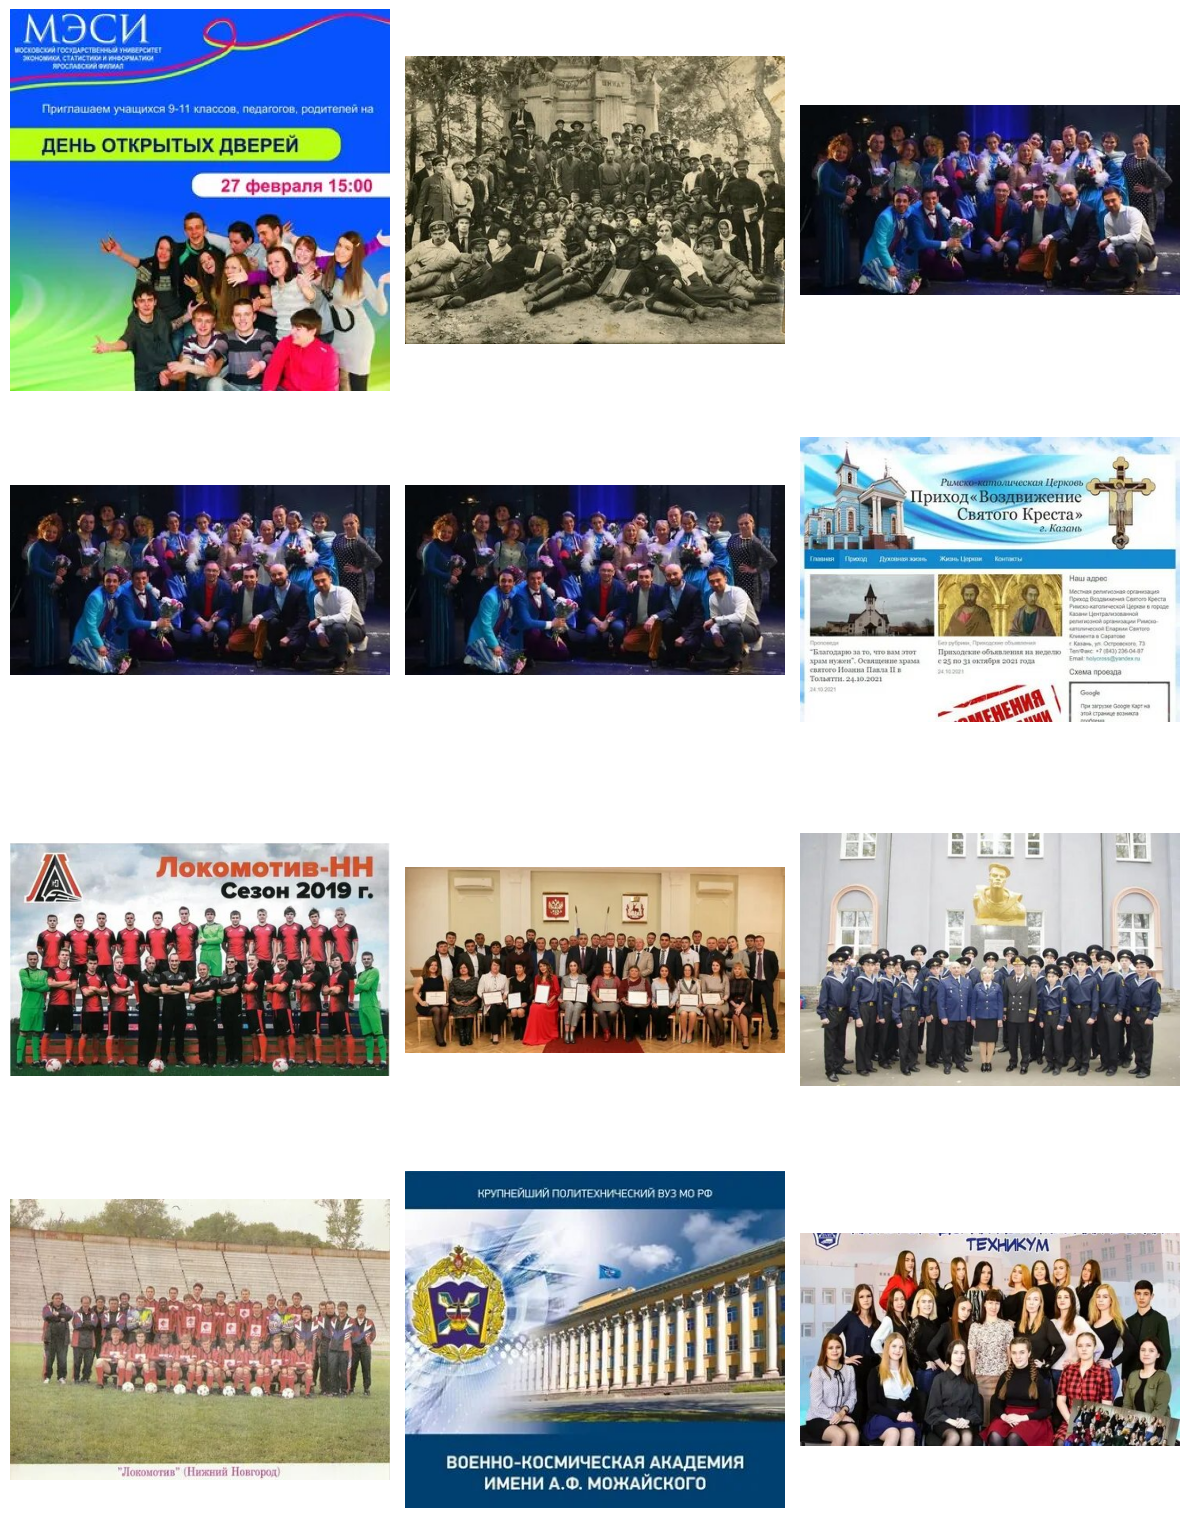

In [121]:
show_images(suspects["image"][:12], cols=3)

как видно, это действительно мусорные объекты. их просто дропаем и получаем датасет без мусора

In [122]:
data_clean = data_scored.loc[data_scored["trash_score"] < threshold, data.columns].copy()
print(f"Отфильтровано {len(suspects)} из {len(data)} фотографий")

Отфильтровано 32 из 12078 фотографий


In [123]:
data_clean_by_wiki_id = data_clean.groupby("WikiData")["image"].agg(list).rename("images").reset_index()
places_with_images = places.merge(data_clean_by_wiki_id, on="WikiData", how="left")
places_with_images

,WikiData,Name,City,search_text,images
0,Q15954283,улица Добролюбова,Екатеринбург,Name: улица Добролюбова. City: Екатеринбург. D...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
1,Q4516884,Чкаловская лестница,Нижний Новгород,Name: Чкаловская лестница. City: Нижний Новгор...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
2,Q4474328,улица Февральской Революции,Екатеринбург,Name: улица Февральской Революции. City: Екате...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
3,Q4343452,Добровольцам-танкистам,Екатеринбург,Name: Добровольцам-танкистам. City: Екатеринбу...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
4,Q4477575,Усадьба Тарасова,Екатеринбург,Name: Усадьба Тарасова. City: Екатеринбург. De...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
...,...,...,...,...,...
291,Q4538889,Ярославский музей-заповедник,Ярославль,Name: Ярославский музей-заповедник. City: Ярос...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
292,Q4538931,Ярославское художественное училище,Ярославль,Name: Ярославское художественное училище. City...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
293,Q55154121,№28 Здание городской электростанции «Луч»,Екатеринбург,Name: №28 Здание городской электростанции «Луч...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
294,Q4165268,Дом Болконского,Ярославль,Name: Дом Болконского. City: Ярославль. Descri...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...


In [124]:
places_with_images.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   WikiData     296 non-null    object
 1   Name         296 non-null    object
 2   City         296 non-null    object
 3   search_text  296 non-null    object
 4   images       296 non-null    object
dtypes: object(5)
memory usage: 11.7+ KB


Здесь предлагаем вам построить RAG с использованием моделей, которые не были представлены на семинаре (включая другие векторные базы данных). Можно воспользоваться материалами по этой ссылке: [data_connection/vectorstores](https://python.langchain.com/v0.1/docs/modules/data_connection/vectorstores/).

!Важно, не забудьте отранжировать чанки текстов с помощью `ragatouille`. На практике порядок текстов в промпте влияет на точность ответа.

In [125]:
from tqdm.auto import tqdm

In [126]:
RAW_KNOWLEDGE_BASE = [
    LangchainDocument(
        page_content=doc.search_text,
        metadata={
            "WikiData": doc.WikiData,
            "Name": doc.Name,
            "City": doc.City,
        },
    ) for doc in tqdm(places_with_images.itertuples(index=False))
]

0it [00:00, ?it/s]

проверим длины документов, чтобы понять, надо ли вообще их бить на чанки

In [127]:
lengths = pd.Series([len(doc.page_content) for doc in RAW_KNOWLEDGE_BASE])
lengths.describe()

count    296.000000
mean     100.381757
std       27.158534
min       52.000000
25%       84.000000
50%       95.000000
75%      111.000000
max      297.000000
dtype: float64

у нас максимальная длина в символах 297, а при разбиении на токены может получиться еще меньше. поэтому разбивать на чанки вообще нет смысла, только потеряем смысл нашего search_text

посмотрим на график распределения токенизированных документов

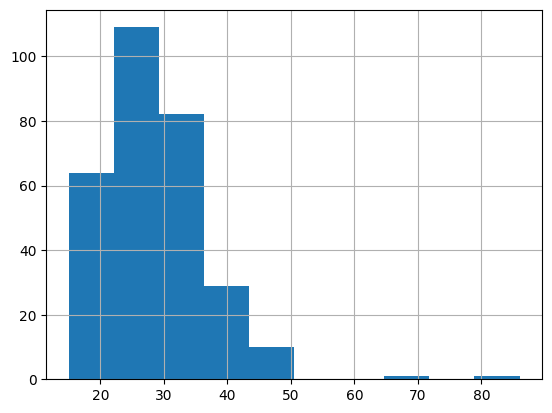

In [128]:
tokenizer = AutoTokenizer.from_pretrained("BAAI/bge-m3")

lengths = [len(tokenizer.encode(doc.search_text)) for doc in places_with_images.itertuples(index=False)]
fig = pd.Series(lengths).hist()
plt.show()

теперь добавим это все в векторную базу данных

In [129]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

embedding_model = HuggingFaceEmbeddings(
    model_name="BAAI/bge-m3",
    model_kwargs={"device": device},
    encode_kwargs={
        "normalize_embeddings": True,
        "batch_size": 16,
    }
)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.27GB            

model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

In [130]:
KNOWLEDGE_VECTOR_DATABASE = FAISS.from_documents(
    documents=RAW_KNOWLEDGE_BASE,
    embedding=embedding_model,
    distance_strategy=DistanceStrategy.COSINE
)

Выполните визуализацию эмбеддингов при помощи метода главных компонент (PCA) и Uniform Manifold Approximation and Projection (UMAP). Пожалуйста, выполните PCA независимо от pacmap.

In [131]:
index = KNOWLEDGE_VECTOR_DATABASE.index
embeddings = index.reconstruct_n(0, index.ntotal)

In [132]:
from sklearn.decomposition import PCA
from umap import UMAP
import matplotlib.pyplot as plt

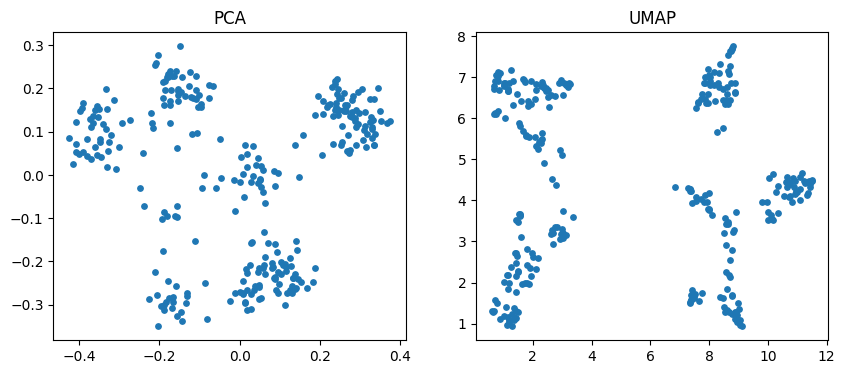

In [133]:
pca_points = PCA(n_components=2).fit_transform(embeddings)
umap_points = UMAP(n_components=2, metric="cosine").fit_transform(embeddings)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, points, title in zip(axes, [pca_points, umap_points], ["PCA", "UMAP"]):
    ax.scatter(points[:, 0], points[:, 1], s=15)
    ax.set_title(title)

plt.show()

проверим запрос и выдачу RAG по нему

In [134]:
user_query = "Какие музей есть в Нижнем Новгороде?"
candidates = KNOWLEDGE_VECTOR_DATABASE.similarity_search(user_query, k=5)

for i, doc in enumerate(candidates):
    print(f"{i+1}. {doc.page_content}")

1. Name: Нижегородский государственный художественный музей. City: Нижний Новгород. Description: один из старейших музеев России, крупнейший музей изобразительного искусства в Нижегородской области.
2. Name: Музей науки «Нижегородская радиолаборатория». City: Нижний Новгород. Description: Нижегородская радиолаборатория
3. Name: Усадьба Добролюбовых. City: Нижний Новгород. Description: единственный в мире музей литературного критика и писателя Николая Александровича Добролюбова, расположенный в Нижнем Новгороде.
4. Name: Музей-квартира А.М. Горького. City: Нижний Новгород. Description: Музей-квартира А. М. Горького (Нижний Новгород)
5. Name: Автозаводский парк культуры и отдыха. City: Нижний Новгород. Description: Автозаводский парк


Вроде выдает нормально. Посчитаем метрику, затем добавим реранкинг и опять потеситируем

# RAGAS (3 балла)

RAGAS - это система, созданная для автоматической оценки эффективности модели RAG. Она представляет собой комплексный инструмент, способный оценить как качество извлечения информации, так и качество созданного текста. Это достигается благодаря использованию различных метрик, которые анализируют разные аспекты ответов, сгенерированных языковой моделью.



## Метрики оценки в RAGAS

### Faithfulness
Оценивает, насколько ответы языковой модели верно передают информацию, содержащуюся в источниках данных. Это критически важно, чтобы гарантировать, что модель не искажает или не меняет информацию при её интерпретации.

---

$
Faithfulness = \frac{\text{|Number of claims that can be inferred from given context|}}{\text{|Total number of claims in the generated answer|}}
$

### Answer Relevancy
Демонстрирует, насколько ответы соответствуют заданным вопросам. Это важный аспект, так как даже правильный ответ с технической точки зрения может быть ненужным, если он не отвечает на конкретный вопрос пользователя.

---

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} cos(E_{g_i}, E_o)$

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} \frac{E_{g_i} \cdot E_o}{\|E_{g_i}\|\|E_o\|}$

Где:

* $E_{g_i}$ - это эмбеддинг сгенерированного ответа $i$

* $E_o$ - это эмбеддинг исходного вопроса.

* $N$ - это количество сгенерированных вопросов, которое по умолчанию равно 3.

### Context Recall и Context Precision
Эти метрики измеряют эффективность модели в учете контекста вопроса для формирования ответа. "Context Recall" оценивает количество использованной информации из контекста в ответе, в то время как "Context Precision" оценивает точность и релевантность использования контекстной информации.

---

* $ \text{context recall} = \frac{\text{|GT sentences that can be attributed to context|}}{\text{|Number of sentences in GT|}} $
* $Context Precision@k = \frac{\sum \text{precision@k}}{\text{total number of relevant items in the top K results}}$
  * $Precision@k = \frac{\text {true positives@k}}{\text{(true positives@k + false positives@k)}}$

### Answer Semantic Similarity
Оценивает степень семантической близости между ответом модели и эталонным ответом. Это позволяет определить, насколько естественно и точно модель способна воссоздавать человеческий язык.

### Answer Correctness
Оценка корректности ответа. Это последний шаг в проверке, чтобы убедиться, предоставляет ли модель точную и достоверную информацию в своем ответе.

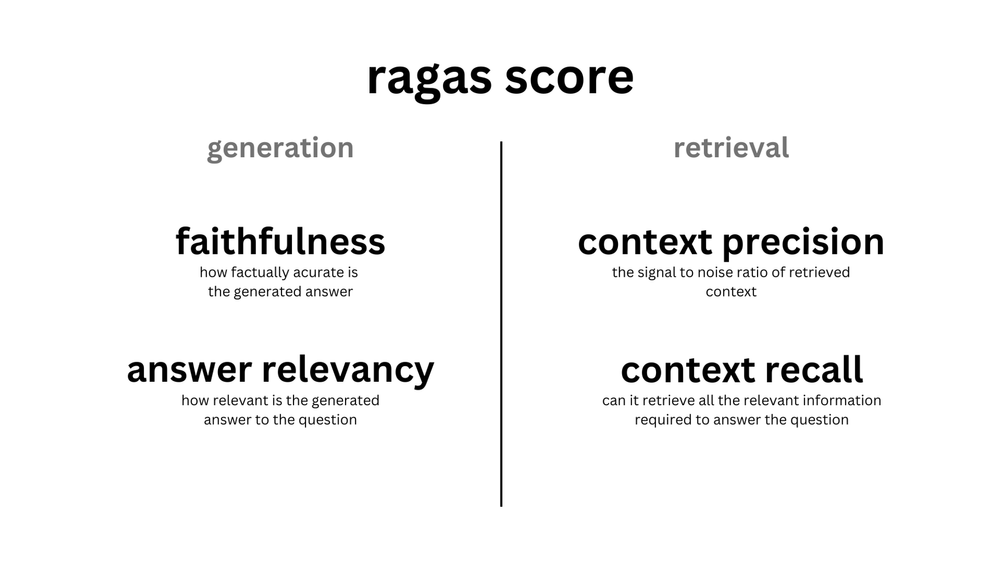

В этом задании вам нужно реализовать метрику answer_relevancy в коде. Опционально за допбаллы можно реализовать другие метрики.

Для этого датасет нужно привести к виду, в котором будут следующие поля:

### 1. question
- Смысл: Эта колонка содержит вопросы, на которые нужно найти ответы. В контексте задач QA, это основная информация, которую модель должна обработать для генерации ответа.
- Пример: "Каковы преимущества RAG?"

### 2. ground_truths
- Смысл: В этой колонке находятся правильные ответы на соответствующие вопросы. Это может использоваться для оценки производительности модели, так как позволяет сравнить сгенерированные ответы с эталонными.
- Пример: "RAG улучшает качество генерации, используя внешние источники информации."

### 3. answer
- Смысл: Эта колонка содержит ответы, которые генерирует модель на основе заданных вопросов. Это может быть результат работы модели, которую вы тестируете или обучаете.
- Пример: "RAG позволяет моделям извлекать информацию из внешних источников, что улучшает их способность отвечать на сложные вопросы."

### 4. contexts
- Смысл: Эта колонка предоставляет контекст или дополнительную информацию, которая может быть полезна для понимания вопроса или для формирования ответа. Это может быть текст, из которого был извлечен ответ, или другие релевантные документы.
- Пример: "RAG (Retrieval-Augmented Generation) — это метод, который использует внешние базы данных для получения информации при генерации текста."

HINT: Поле question можно тоже сгенерировать. Например, можно попросить модель задать вопрос по описанию изображения.

HINT: Для answer_relevancy нужны не все поля

HINT: Инференс такого эксперимента может быть долгим. План минимум: возьмите 100 случайных сэмплов.

In [135]:
model_id = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(model_id)
llm = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)

READER_LLM = pipeline(
    model=llm,
    tokenizer=tokenizer,
    task="text-generation",
    do_sample=True,
    temperature=0.2,
    repetition_penalty=1.1,
    return_full_text=False,
    max_new_tokens=500
)

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

In [136]:
prompt_in_chat_format = [
    {
        "role": "system",
        "content": """Using the information contained in the context,
give a comprehensive answer to the question.
Respond only to the question asked, response should be concise and relevant to the question.
Provide the number of the source document when relevant.
If the answer cannot be deduced from the context, do not give an answer.""",
    },
    {
        "role": "user",
        "content": """Context: {context}
---
Now here is the question you need to answer.

Question: {question}""",
    },
]

RAG_PROMPT_TEMPLATE = tokenizer.apply_chat_template(
    prompt_in_chat_format,
    tokenize=False,
    add_generation_prompt=True
)

In [162]:
def data_preprocess(llm, vector_db, questions, prompt_template=RAG_PROMPT_TEMPLATE, 
                    k=5, batch_size=4, reranker=None, fetch_k=20):    
    data = []
    with tqdm(total=len(questions), desc="Обработка вопросов", unit="вопр.") as progress:
        for start in range(0, len(questions), batch_size):
            batch_questions = questions[start : start + batch_size]
            batch_contexts = []
            batch_prompts = []

            for question in batch_questions:
                search_k = max(k, fetch_k) if reranker is not None else k
                candidates = [doc.page_content for doc in vector_db.similarity_search(question, k=search_k)]
                if reranker is not None and candidates:
                    ranked = reranker.rank(question, candidates, top_k=min(k, len(candidates)), return_documents=True)
                    candidates = [item["text"] for item in ranked]
                context = "\nExtracted documents:\n" + "\n\n".join(f"Document {i}:::\n{doc}" for i, doc in enumerate(candidates))
                batch_contexts.append(candidates)
                batch_prompts.append(prompt_template.format(question=question, context=context))

            outputs = llm(batch_prompts, batch_size=batch_size, return_full_text=False)
            batch_answers = [out[0]["generated_text"].strip() for out in outputs]
            data.extend(zip(batch_questions, batch_contexts, batch_answers, strict=True))
            progress.update(len(batch_answers))

    return pd.DataFrame(data, columns=["question", "contexts", "answer"])

In [138]:
def answer_relevancy(q_embed, ans_embed):
  return cosine_similarity(q_embed, ans_embed).mean()

просто посмотрим на примеры вопросов и ответов

In [139]:
places_with_images.sample(10)

,WikiData,Name,City,search_text,images
186,Q4476791,Уральский турбинный завод,Екатеринбург,Name: Уральский турбинный завод. City: Екатери...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
236,Q4322970,Ново-Тихвинский монастырь,Екатеринбург,Name: Ново-Тихвинский монастырь. City: Екатери...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
227,Q4221355,Спасо-Афанасиевский Ярославский монастырь,Ярославль,Name: Спасо-Афанасиевский Ярославский монастыр...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
32,Q1508336,Храм Сергия Радонежского,Нижний Новгород,Name: Храм Сергия Радонежского. City: Нижний Н...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
128,Q42296354,Дом контор,Екатеринбург,Name: Дом контор. City: Екатеринбург. Descript...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
162,Q19916149,Храм Казанской иконы Божией Матери,Владимир,Name: Храм Казанской иконы Божией Матери. City...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
273,Q4504106,Центральная городская библиотека им. А. И. Гер...,Екатеринбург,Name: Центральная городская библиотека им. А. ...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
62,Q21008370,Старообрядческий храм Иоанна Златоуста в Коров...,Ярославль,Name: Старообрядческий храм Иоанна Златоуста в...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
127,Q4128054,Второй Дом Советов,Екатеринбург,Name: Второй Дом Советов. City: Екатеринбург. ...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
27,Q4306319,Музей истории города Ярославля,Ярославль,Name: Музей истории города Ярославля. City: Яр...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...


In [140]:
questions = ["Где находится Чкаловская лестница в Нижнем Новгороде?",
            "Что такое Церковь Никиты Великомученика?",
            "В каком городе расположена Владимирская духовная семинария?"]

data_preprocess(READER_LLM, KNOWLEDGE_VECTOR_DATABASE, questions)

Обработка вопросов:   0%|          | 0/3 [00:00<?, ?вопр./s]

,question,contexts,answer
0,Где находится Чкаловская лестница в Нижнем Нов...,[Name: Чкаловская лестница. City: Нижний Новго...,Чкаловская лестница находится на Волжском отко...
1,Что такое Церковь Никиты Великомученика?,[Name: Церковь Никиты Великомученика. City: Вл...,Церковь Никиты Великомученика — это церковь в ...
2,В каком городе расположена Владимирская духовн...,[Name: Владимирская духовная семинария. City: ...,Владимирская духовная семинария расположена в ...


тепепрь сгенерируем 100 вопросов, чтобы протестировать наш RAG

In [141]:
from tqdm.auto import tqdm

In [142]:
def generate_questions(llm, tokenizer, search_texts, batch_size=4):    
    messages = [
        {
        "role": "system",
        "content": (
            """По карточке достопримечательности составь один вопрос на русском.

            - Вопрос должен быть понятен человеку, который не видел карточку.
            - Укажи название достопримечательности или признаки, по которым её можно узнать.
            - Спрашивай только о факте, который прямо указан в карточке.
            - Если в описании есть конкретная деталь, спроси о ней. Если фактов мало, спроси о городе или типе объекта.
            - Выведи только вопрос, одной строкой.
            
            Пример карточки:
            Название — Чкаловская лестница. Город — Нижний Новгород.
            Описание — лестница на Волжском откосе.
            
            Вопрос: На каком откосе находится Чкаловская лестница?"""
        ),
        },
        {"role": "user", 
         "content": "{context}"},
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    prompts = [prompt.format(context=st) for st in search_texts]

    questions = []
    with tqdm(total=len(prompts), desc="Генерация вопросов", unit="вопр.") as progress:
        for start in range(0, len(prompts), batch_size):
            batch = prompts[start : start + batch_size]
            outputs = llm(
                batch,
                batch_size=batch_size,
                max_new_tokens=64,
                return_full_text=False,
            )
            questions.extend(
                output[0]["generated_text"].strip() for output in outputs
            )
            progress.update(len(outputs))

    return questions

посмотрим распределение городов в датасете, чтобы грамотно выбрать строки, с которых будем генерировать вопросы

<Axes: >

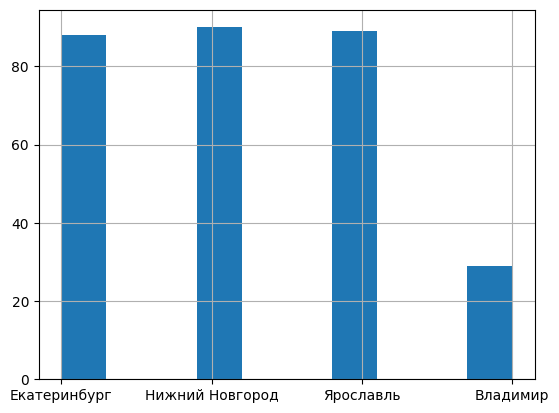

In [143]:
places_with_images["City"].hist()

In [144]:
places_with_images["City"].value_counts()

City
Нижний Новгород    90
Ярославль          89
Екатеринбург       88
Владимир           29
Name: count, dtype: int64

тогда возьму по 25 строк по каждому горорду, чтобы получилось одинаковое распределение

In [145]:
texts = places_with_images.groupby("City").sample(n=25, random_state=42)
texts

,WikiData,Name,City,search_text,images
287,Q4478034,Успенский Княгинин монастырь,Владимир,Name: Успенский Княгинин монастырь. City: Влад...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
215,Q107422934,Дом-музей Столетовых,Владимир,Name: Дом-музей Столетовых. City: Владимир. De...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
161,Q4113284,Владимирский планетарий,Владимир,Name: Владимирский планетарий. City: Владимир....,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
221,Q18400985,"Памятник природы ""Лесной парк Дружба""",Владимир,"Name: Памятник природы ""Лесной парк Дружба"". C...",[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
112,Q21639718,Здание городской думы,Владимир,Name: Здание городской думы. City: Владимир. D...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
...,...,...,...,...,...
82,Q60850718,Храм Архангела Михаила,Ярославль,Name: Храм Архангела Михаила. City: Ярославль....,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
266,Q4538877,Ярославский дворец молодёжи,Ярославль,Name: Ярославский дворец молодёжи. City: Яросл...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
226,Q25394333,Мост Волжские Ворота,Ярославль,Name: Мост Волжские Ворота. City: Ярославль. D...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...
89,Q13668162,Петропавловский парк,Ярославль,Name: Петропавловский парк. City: Ярославль. D...,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...


In [146]:
texts = places_with_images.groupby("City").sample(n=25, random_state=42)["search_text"]
questions = generate_questions(READER_LLM, tokenizer, texts)
questions[:5]

Генерация вопросов:   0%|          | 0/100 [00:00<?, ?вопр./s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


['Где находится Успенский Княгинин монастырь?',
 'Как называется музей в городе Владимире, посвящённый жизни и деятельности учёного-физика и генерала Столетовых?',
 'Где находится Владимирский планетарий?',
 'Где расположен лесной парк «Дружба»?',
 'Где расположено здание городской думы в Владимире?']

теперь создадим ответы на сгенерированные вопросы

In [147]:
data_answers = data_preprocess(READER_LLM, KNOWLEDGE_VECTOR_DATABASE, questions)
data_answers[["question", "answer"]].head()

Обработка вопросов:   0%|          | 0/100 [00:00<?, ?вопр./s]

,question,answer
0,Где находится Успенский Княгинин монастырь?,Успенский Княгинин монастырь находится в город...
1,"Как называется музей в городе Владимире, посвя...","Музей в городе Владимире, посвящённый жизни и ..."
2,Где находится Владимирский планетарий?,Владимирский планетарий находится в городе Вла...
3,Где расположен лесной парк «Дружба»?,Лесной парк «Дружба» расположен в городе Влади...
4,Где расположено здание городской думы в Владим...,Здание городской думы находится в городе Влади...


теперь надо опять по сгенерированному ответу сгенерировать по 3 вопроса, которые мы в дальнейшем будем сравнивать с изначальными вопросами для вычисления метрики answer_relevancy

In [148]:
def gen_3_questions(llm, tokenizer, answers, batch_size=4):
    messages = [
        {
            "role": "system",
            "content": """
                Сформулируй три вопроса на русском, на каждый из которых
                можно ответить данным текстом. Выведи только вопросы,
                по одному на строку, без нумерации.
            """
        },
        {
            "role": "user",
            "content": "{answer}"
        }
    ]

    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    prompts = [prompt.format(answer=ans) for ans in answers]
    
    questions = []
    with tqdm(total=len(prompts), desc="Восстановление вопросов", unit="отв.") as progress:
        for start in range(0, len(prompts), batch_size):
            batch = prompts[start : start + batch_size]
            outputs = llm(batch, batch_size=batch_size, max_new_tokens=128, return_full_text=False,
            )

            for output in outputs:
                questions.append([line.strip() for line in output[0]["generated_text"].splitlines() if line.strip()])

            progress.update(len(outputs))

    return questions

In [149]:
generated = gen_3_questions(READER_LLM, tokenizer, data_answers["answer"].tolist())
generated[:3]

Восстановление вопросов:   0%|          | 0/100 [00:00<?, ?отв./s]

[['Где находится Успенский Княгинин монастырь?',
  'Какой город является местом расположения Успенского Княгинина монастыря?',
  'Что такое Успенский Княгинин монастырь и где он расположен?'],
 ['Как называется музей в городе Владимире, посвящённый Столетовому?',
  'Кем является Столетов, о котором идёт речь в музее?',
  'Где находится Дом-музей Столетовых?'],
 ['Где находится Владимирский планетарий?',
  'Какой город является местом расположения Владимирского планетария?',
  'Что такое Владимирский планетарий?']]

# Протестируйте ваш RAG (3 балла)

теперь уже посчитаем скоры пока что без реранкинга

In [150]:
scores = []
for question, group in zip(data_answers["question"], generated):
    q_embed, *generated_embeds = embedding_model.embed_documents([question, *group])
    scores.append(answer_relevancy([q_embed], generated_embeds))

data_answers["answer_relevancy"] = scores
data_answers["answer_relevancy"].mean()

np.float64(0.8653479780998005)

In [151]:
data_answers.head()

,question,contexts,answer,answer_relevancy
0,Где находится Успенский Княгинин монастырь?,[Name: Успенский Княгинин монастырь. City: Вла...,Успенский Княгинин монастырь находится в город...,0.962887
1,"Как называется музей в городе Владимире, посвя...",[Name: Дом-музей Столетовых. City: Владимир. D...,"Музей в городе Владимире, посвящённый жизни и ...",0.779842
2,Где находится Владимирский планетарий?,[Name: Владимирский планетарий. City: Владимир...,Владимирский планетарий находится в городе Вла...,0.958302
3,Где расположен лесной парк «Дружба»?,"[Name: Памятник природы ""Лесной парк Дружба"". ...",Лесной парк «Дружба» расположен в городе Влади...,0.966263
4,Где расположено здание городской думы в Владим...,[Name: Здание городской думы. City: Владимир. ...,Здание городской думы находится в городе Влади...,0.817066


Теперт добавим реранкинг, посмотрим, улучшится ли скор

In [ ]:
# ragatouille устаревшая библиотека для colBERT. буду использовать другую идею CrossEncoder
# чтобы не было конфликтов версий
# from sentence_transformers import CrossEncoder

In [157]:
reranker = CrossEncoder("BAAI/bge-reranker-v2-m3")

config.json:   0%|          | 0.00/795 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

INFO: Tried to clean up context but failed!


In [163]:
data_reranked = data_preprocess(READER_LLM, KNOWLEDGE_VECTOR_DATABASE, data_answers["question"].tolist(), 
                                reranker=reranker)

Обработка вопросов:   0%|          | 0/100 [00:00<?, ?вопр./s]

In [164]:
generated_reranked = gen_3_questions(READER_LLM, tokenizer, data_reranked["answer"].tolist())

Восстановление вопросов:   0%|          | 0/100 [00:00<?, ?отв./s]

In [165]:
scores = []
for question, group in zip(data_reranked["question"], generated_reranked, strict=True):
    q_embed, *generated_embeds = embedding_model.embed_documents([question, *group])
    scores.append(answer_relevancy([q_embed], generated_embeds))

data_reranked["answer_relevancy"] = scores

In [167]:
baseline = data_answers["answer_relevancy"].mean()
reranked = data_reranked["answer_relevancy"].mean()
print(f"FAISS: {baseline:.4f}")
print(f"FAISS + реранкинг: {reranked:.4f}")
print(f"delta: {reranked - baseline:+.4f}")

FAISS: 0.8653
FAISS + реранкинг: 0.8714
delta: +0.0061


### Итоги

Проанализировав полученный датасет, удалось избавиться от нерелевантных данных, сгруппировать по WikiData и выделить 296 лучших строчек. После чего вначале была построена обычная система RAG с поиском по векторной базе FAISS. Затем был добавлен cross-encoder, добавивший к ранкингу 0.0061 релевантности ответа. Это маленький прирост, но все же прирост. Вопрос производительности и необходимости добавления cross-encoder с этой точки зрения не был исследован, но это можно добавить в список будущих доработок в целом.

Идея сравнения именно вопросов была реализована, тк если модель хорошо сможет задавать вопросы по полученному описанию (которое в свою очередь получено с использованием нашей RAG системы), то можно предположить, что заданные вопросы должны быть векторно близки к изначальным, по которым и строилось описание. Однако понятное дело, что это не дает 100% гарантии верности рассуждений LLM и в целом 100% оценки качества полученного поиска по документам, поэтому всегда надо смотреть на совокупность метрик.

# Дополнительная часть (+3 балла)

In [ ]:
# your code here